In [9]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import Dropdown, IntSlider, interact

# Si el notebook está dentro de la carpeta 'dataset', usa '.'
# Si está un nivel afuera, usa 'dataset'
DATASET_DIR = "dataset"
COLUMNS = ["ax", "ay", "az", "gx", "gy", "gz"]
SAMPLING_RATE_HZ = 100


In [10]:
files_by_class = {}

# Carpetas a ignorar obligatoriamente
IGNORE_DIRS = {"build", ".git", ".cache", "__pycache__", ".ipynb_checkpoints"}

if os.path.exists(DATASET_DIR):
  for entry in sorted(os.listdir(DATASET_DIR)):
    folder_path = os.path.join(DATASET_DIR, entry)
    if os.path.isdir(folder_path) and entry not in IGNORE_DIRS:
      # Solo busca archivos .csv dentro de cada clase (A, IDLE, etc.)
      csv_files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))
      if csv_files:
        files_by_class[entry] = csv_files

print("Resumen de clases válidas detectadas:")
for cls, files in files_by_class.items():
  print(f"  • {cls}: {len(files)} muestras")

Resumen de clases válidas detectadas:
  • A: 54 muestras
  • IDLE: 46 muestras
  • quarantine_A: 2 muestras
  • quarantine_IDLE: 34 muestras


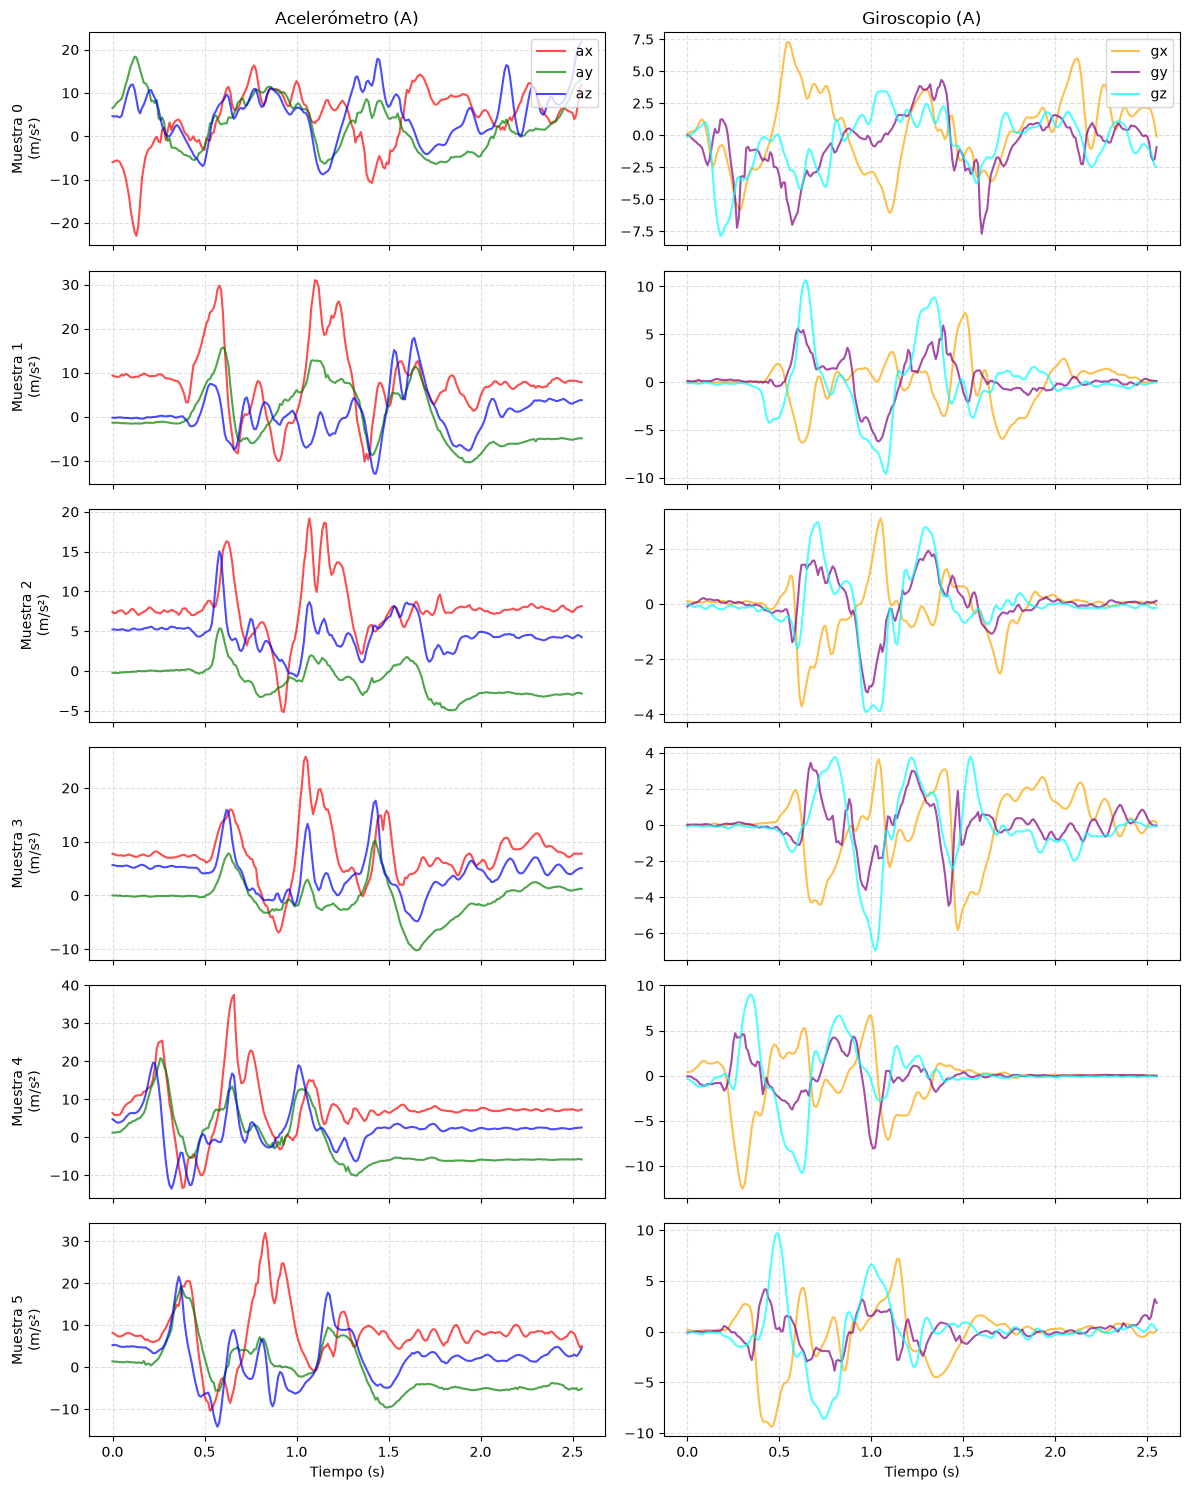

In [11]:
%matplotlib inline
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

archivos_idle = sorted(glob.glob("dataset/A/*.csv"))[:6] # Primeras 6 muestras

fig, axes = plt.subplots(len(archivos_idle), 2, figsize=(12, 2.5 * len(archivos_idle)), sharex=True)

for i, ruta in enumerate(archivos_idle):
    df = pd.read_csv(ruta, header=None, names=["ax", "ay", "az", "gx", "gy", "gz"])
    t = np.arange(len(df)) / 100.0
    
    # Aceleración
    axes[i, 0].plot(t, df["ax"], color="red", alpha=0.7, label="ax")
    axes[i, 0].plot(t, df["ay"], color="green", alpha=0.7, label="ay")
    axes[i, 0].plot(t, df["az"], color="blue", alpha=0.7, label="az")
    axes[i, 0].set_ylabel(f"Muestra {i}\n(m/s²)")
    axes[i, 0].grid(True, linestyle="--", alpha=0.4)
    if i == 0:
        axes[i, 0].set_title("Acelerómetro (A)")
        axes[i, 0].legend(loc="upper right")

    # Giroscopio
    axes[i, 1].plot(t, df["gx"], color="orange", alpha=0.7, label="gx")
    axes[i, 1].plot(t, df["gy"], color="purple", alpha=0.7, label="gy")
    axes[i, 1].plot(t, df["gz"], color="cyan", alpha=0.7, label="gz")
    axes[i, 1].grid(True, linestyle="--", alpha=0.4)
    if i == 0:
        axes[i, 1].set_title("Giroscopio (A)")
        axes[i, 1].legend(loc="upper right")

axes[-1, 0].set_xlabel("Tiempo (s)")
axes[-1, 1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

In [12]:
import glob
import os
import shutil
import numpy as np
import pandas as pd

DATASET_DIR = "dataset"
COLUMNS = ["ax", "ay", "az", "gx", "gy", "gz"]
SAMPLING_RATE_HZ = 100
EXPECTED_SAMPLES = 256

# --- Critères de validation ---
# Classe A (geste actif)
A_MIN_PEAK_GYRO = 3.0  # Vitesse angulaire max requise (rad/s)
A_MIN_TIME_PEAK = 0.3  # Début min du pic temporel (s)
A_MAX_TIME_PEAK = 1.8  # Fin max du pic temporel (s)

# Classe IDLE (repos / manipulation douce)
IDLE_MAX_PEAK_GYRO = 2.5  # Rejette si dépassement d'un seuil de mouvement franc


def valider_fichier(file_path, classe):
  try:
    df = pd.read_csv(file_path, header=None, names=COLUMNS)
  except Exception as e:
    return False, f"Erreur de lecture : {e}"

  if len(df) != EXPECTED_SAMPLES:
    return False, f"Taille invalide ({len(df)}/{EXPECTED_SAMPLES} lignes)"

  # Norme Euclidienne de la vitesse angulaire : ||gyro||
  gyro_norm = np.sqrt(df["gx"] ** 2 + df["gy"] ** 2 + df["gz"] ** 2)
  max_gyro = gyro_norm.max()
  peak_time = gyro_norm.idxmax() / SAMPLING_RATE_HZ

  if classe == "A":
    if max_gyro < A_MIN_PEAK_GYRO:
      return False, f"Pic trop faible ({max_gyro:.2f} rad/s < {A_MIN_PEAK_GYRO})"
    if peak_time < A_MIN_TIME_PEAK:
      return False, f"Geste trop précoce (pic à {peak_time:.2f} s)"
    if peak_time > A_MAX_TIME_PEAK:
      return False, f"Geste tardif / incomplet (pic à {peak_time:.2f} s)"
    return True, f"OK (pic {max_gyro:.1f} rad/s à {peak_time:.2f} s)"

  elif classe == "IDLE":
    if max_gyro > IDLE_MAX_PEAK_GYRO:
      return False, f"Mouvement parasite ({max_gyro:.2f} rad/s)"
    return True, f"OK (max {max_gyro:.2f} rad/s)"

  return True, "Classe sans règle définie"


# --- Exécution du nettoyage ---
stats = {}

for classe in ["A", "IDLE"]:
  dossier_classe = os.path.join(DATASET_DIR, classe)
  if not os.path.exists(dossier_classe):
    continue

  quarantine_dir = os.path.join(DATASET_DIR, f"quarantine_{classe}")
  os.makedirs(quarantine_dir, exist_ok=True)

  fichiers = sorted(glob.glob(os.path.join(dossier_classe, "*.csv")))
  valides, rejetes = 0, 0

  print(f"\n--- Filtrage classe '{classe}' ({len(fichiers)} fichiers) ---")
  for f in fichiers:
    ok, raison = valider_fichier(f, classe)
    nom_fichier = os.path.basename(f)

    if ok:
      valides += 1
    else:
      rejetes += 1
      print(f" [REJET] {nom_fichier} -> {raison}")
      shutil.move(f, os.path.join(quarantine_dir, nom_fichier))

  stats[classe] = (valides, rejetes)

print("\n" + "=" * 40)
print("BILAN DU NETTOYAGE :")
for c, (v, r) in stats.items():
  print(f" - {c:5s} : {v} conservés, {r} mis en quarantaine")
print("=" * 40)


--- Filtrage classe 'A' (54 fichiers) ---

--- Filtrage classe 'IDLE' (46 fichiers) ---

BILAN DU NETTOYAGE :
 - A     : 54 conservés, 0 mis en quarantaine
 - IDLE  : 46 conservés, 0 mis en quarantaine


In [13]:
import os
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

DATASET_DIR = "dataset"
CLASSES = ["A", "IDLE"]
SAMPLES_PER_GESTURE = 256
CHANNELS = 6
COLUMNS = ["ax", "ay", "az", "gx", "gy", "gz"]

# --- 1. Chargement du dataset nettoyé ---
X, y = [], []

for class_idx, class_name in enumerate(CLASSES):
    csv_files = sorted(glob.glob(os.path.join(DATASET_DIR, class_name, "*.csv")))
    for f in csv_files:
        df = pd.read_csv(f, header=None, names=COLUMNS)
        if len(df) == SAMPLES_PER_GESTURE:
            X.append(df.values)
            y.append(class_idx)

X = np.array(X, dtype=np.float32) # Shape: (N, 256, 6)
y = np.array(y, dtype=np.int32)

print(f"Dataset total : {X.shape[0]} échantillons {X.shape[1:]}")
for idx, name in enumerate(CLASSES):
    print(f" - {name} : {np.sum(y == idx)}")

# --- 2. Normalisation (Z-score global par canal) ---
mean = np.mean(X, axis=(0, 1), keepdims=True)
std = np.std(X, axis=(0, 1), keepdims=True) + 1e-6
X_norm = (X - mean) / std

# Sauvegarde des paramètres de normalisation pour le firmware C
print("\nParamètres à intégrer dans le firmware C :")
print(f"float norm_mean[6] = {{{', '.join(f'{v:.6f}f' for v in mean.flatten())}}};")
print(f"float norm_std[6]  = {{{', '.join(f'{v:.6f}f' for v in std.flatten())}}};")

# Split Stratifié 80% Train / 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y, test_size=0.2, random_state=42, stratify=y
)

# --- 3. Architecture 1D-CNN compacte pour STM32F411 ---
model = models.Sequential([
    layers.Input(shape=(SAMPLES_PER_GESTURE, CHANNELS)),
    layers.Conv1D(16, kernel_size=5, padding="same", activation="relu"),
    layers.MaxPooling1D(pool_size=2),  # (128, 16)
    layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling1D(pool_size=2),  # (64, 32)
    layers.GlobalAveragePooling1D(),    # Réduction à un vecteur de 32 (évite le surapprentissage)
    layers.Dense(16, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

# --- 4. Entraînement ---
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=40,
    batch_size=8,
    verbose=1
)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrécision sur le jeu de test : {acc * 100:.2f}%")

# --- 5. Quantification Post-Training Int8 (TFLM) ---
# 1. Générateur représentatif strict avec casting explicite
def representative_dataset_gen():
  # Utilise les échantillons d'entraînement
  for sample in X_train:
    # Forme attendue : (1, 256, 6) en float32
    tensor = np.expand_dims(sample, axis=0).astype(np.float32)
    yield [tensor]


# 2. Configuration du convertisseur
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_gen

# Verrouiller strictement sur les opérations entières INT8 (pas de fallback float)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

# Forcer les entrées et sorties du modèle en INT8 pur
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Bloquer toute opération restant en flottant (déclenchera une exception si une op refuse l'int8)
converter._experimental_enforce_full_integer_quantization = True
converter._experimental_disable_per_channel_quantization_for_dense_layers = True

tflite_quant_model = converter.convert()

with open("model_gesture_int8.tflite", "wb") as f:
  f.write(tflite_quant_model)

print(
    f"\nModèle TFLite Int8 généré : {len(tflite_quant_model)} octets"
    f" (~{len(tflite_quant_model)//1024} KB)"
)

# --- 6. Export en tableau C pour Zephyr (model_data.h) ---
with open("model_data.h", "w") as f:
    f.write("#ifndef MODEL_DATA_H_\n#define MODEL_DATA_H_\n\n")
    f.write("#include <zephyr/types.h>\n\n")
    f.write("#include <zephyr/toolchain.h>\n")
    f.write("#include <zephyr/types.h>\n\n")    
    f.write(f"const unsigned int g_model_len = {len(tflite_quant_model)};\n")
    f.write("const unsigned char g_model[] __aligned(4) = {\n  ")
    for i, b in enumerate(tflite_quant_model):
        f.write(f"0x{b:02x}, ")
        if (i + 1) % 12 == 0:
            f.write("\n  ")
    f.write("\n};\n\n#endif /* MODEL_DATA_H_ */\n")

print("Fichier 'model_data.h' généré avec succès pour intégration dans Zephyr.")

Dataset total : 100 échantillons (256, 6)
 - A : 54
 - IDLE : 46

Paramètres à intégrer dans le firmware C :
float norm_mean[6] = {4.483182f, -1.584734f, -0.164688f, -0.084898f, -0.010373f, -0.078183f};
float norm_std[6]  = {6.323884f, 4.822824f, 7.081272f, 1.798846f, 0.938258f, 1.596378f};


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 256, 16)        │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 128, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,626 (10.26 KB)

 Trainable params: 2,626 (10.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5375 - loss: 0.6351 - val_accuracy: 0.6000 - val_loss: 0.6063
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5875 - loss: 0.5546 - val_accuracy: 0.6500 - val_loss: 0.5395
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6875 - loss: 0.4945 - val_accuracy: 0.7000 - val_loss: 0.4908
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8000 - loss: 0.4393 - val_accuracy: 0.8000 - val_loss: 0.4439
Epoch 5/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8625 - loss: 0.3803 - val_accuracy: 0.8000 - val_loss: 0.3975
Epoch 6/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9125 - loss: 0.3186 - val_accuracy: 0.8500 - val_loss: 0.3497
Epoch 7/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9250 - loss: 0.2579 - val_accuracy: 0.8500 - val_loss: 0.3009
Epoch 8/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9625 - loss: 0.2024 - val_accuracy: 0.9000 - val_loss

INFO:tensorflow:Assets written to: /tmp/tmpl_38bozk/assets


Saved artifact at '/tmp/tmpl_38bozk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 6), dtype=tf.float32, name='keras_tensor_24')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140454963484608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963487728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963485328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963487008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963490608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963481008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963488688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454963486768: TensorSpec(shape=(), dtype=tf.resource, name=None)

Modèle TFLite Int8 généré : 10800 octets (~10 KB)
Fichier 'model_data.h' généré avec succès pour intégration dans Zephyr.


  warnings.warn(
W0000 00:00:1793261233.323358   61625 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1793261233.323373   61625 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1793261233.323470   61625 reader.cc:83] Reading SavedModel from: /tmp/tmpl_38bozk
I0000 00:00:1793261233.323740   61625 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793261233.323747   61625 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpl_38bozk
I0000 00:00:1793261233.325633   61625 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1793261233.335941   61625 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpl_38bozk
I0000 00:00:1793261233.339716   61625 loader.cc:484] SavedModel load for tags { serve }; Status: success: OK. Took 16250 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1793261233.390552   61625 flat

In [14]:
import warnings
import numpy as np
import tensorflow as tf

# Masque le warning de dépréciation LiteRT pour garder la sortie propre
with warnings.catch_warnings():
  warnings.simplefilter("ignore")
  interpreter = tf.lite.Interpreter(model_content=tflite_quant_model)
  interpreter.allocate_tensors()

inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

print("=== TENSEUR D'ENTRÉE ===")
print("Type   :", inp["dtype"])
print("Shape  :", inp["shape"])
print(
    f"Quant  : scale = {inp['quantization'][0]:.8f}, zero_point ="
    f" {inp['quantization'][1]}"
)

print("\n=== TENSEUR DE SORTIE ===")
print("Type   :", out["dtype"])
print("Shape  :", out["shape"])
print(
    f"Quant  : scale = {out['quantization'][0]:.8f}, zero_point ="
    f" {out['quantization'][1]}"
)

# Liste exhaustive de tous les types de tenseurs dans le modèle
types_tenseur = set(
    t["dtype"] for t in interpreter.get_tensor_details() if "dtype" in t
)
print("\n=== DTYPES PRÉSENTS DANS LE GRAPHE ===")
for t in types_tenseur:
  print(f" - {t}")

=== TENSEUR D'ENTRÉE ===
Type   : <class 'numpy.int8'>
Shape  : [  1 256   6]
Quant  : scale = 0.07061685, zero_point = -5

=== TENSEUR DE SORTIE ===
Type   : <class 'numpy.int8'>
Shape  : [1 2]
Quant  : scale = 0.00390625, zero_point = -128

=== DTYPES PRÉSENTS DANS LE GRAPHE ===
 - <class 'numpy.int32'>
 - <class 'numpy.int8'>
